# c(RGDfV): conformations of a cyclic peptide, written in one labelling

The state-0 (unscaled) ensemble of the explicit-solvent REST2 ladder, clustered with the
symmetry-first `t_hdbscan` and drawn with every frame in the atom labelling **nearest one reference
frame**. c(RGDfV) has two symmetry operations on its torsions, the phenyl ring flip and the swap of
valine's two methyls, and they combine, so the group has four elements and the two orbits behave
differently under a one-angle fold.

The definitions and the limits are in
[Methods: analysis, symmetry-aware clustering and the torsion representation](../../../openmm_methods/analysis/clustering-and-symmetry.md);
this page shows the results.

In [1]:
import os, pathlib, tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mdtraj as md
from rdkit import Chem
from rdkit.Chem.Draw import rdMolDraw2D
from IPython.display import SVG, Image, display
import md_tools
from md_tools.analysis import (TorsionDefinitions, SymmetricTorsionDescriptor, enumerate_symmetry,
                               t_hdbscan, verify_atom_mapping, group_name, draw_symmetry_operation,
                               draw_representative_structures, strip_nonpolar_hydrogens)

# The registered dataset is found through $MD_DATA, and the resolved path is deliberately NOT printed.
DATASET = "2026/hpREST2/RGDfV-explicit-HMR-REST2"
ROOT = pathlib.Path(os.environ["MD_DATA"]) / DATASET
print("dataset:", DATASET, "| found" if ROOT.is_dir() else "| MISSING")
print("md-tools", md_tools.__version__, "+ the unreleased THDBSCAN.density_peak / align_all and "
      "SymmetricTorsionDescriptor.align_to_reference")
scratch = pathlib.Path(tempfile.mkdtemp())          # figures that a helper writes to disk

dataset: 2026/hpREST2/RGDfV-explicit-HMR-REST2 | found
md-tools 0.6.5 + the unreleased THDBSCAN.density_peak / align_all and SymmetricTorsionDescriptor.align_to_reference


## 1. The data

Registered dataset `hpREST2/RGDfV-explicit-HMR-REST2`: an 8-state REST2 ladder, tau from 0 to 0.5,
500 ns per replica, three independent runs. **State 0 is the unscaled Hamiltonian**, so its
trajectory is the physical ensemble and is the only one used here. Each run is read at stride 75
(375 ps) and the three are joined: 3 x 1334 = 4002 frames, under the 10 000-frame limit of the exact
precomputed distance.

CC(C)[C@@H]1NC(=O)[C@@H](Cc2ccccc2)NC(=O)[C@H](CC(=O)[O-])NC(=O)CNC(=O)[C@H](CCCNC(N)=[NH2+])NC1=O | 79 atoms | 4002 frames
atom mapping: identity | identity verified: elements and the full bond graph agree under this mapping


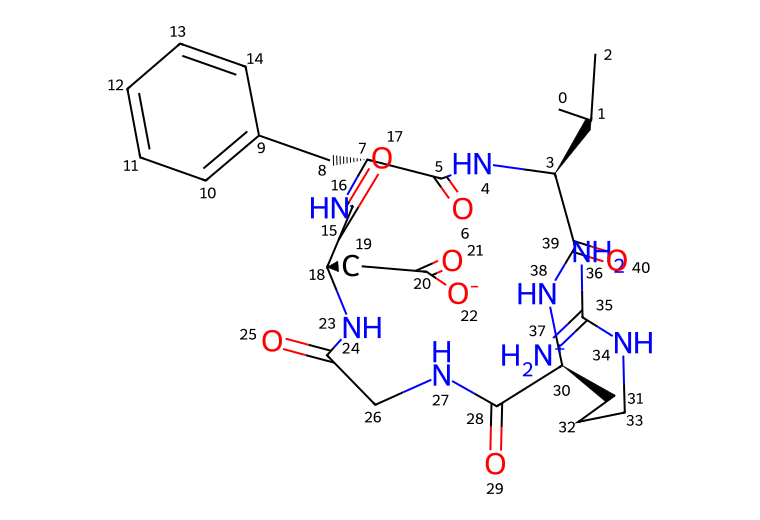

In [2]:
mol = Chem.SDMolSupplier(str(ROOT / "system/built.sdf"), removeHs=False)[0]
parts = [md.load(str(ROOT / f"REST2-run{r}/md_script/solute_state0_prod1.nc"),
                 top=str(ROOT / "system/built.solute.pdb"))[::75] for r in (1, 2, 3)]
traj = parts[0].join(parts[1]).join(parts[2])
mapping, why = verify_atom_mapping(mol, [(b[0].index, b[1].index) for b in traj.topology.bonds],
                                   [a.element.symbol for a in traj.topology.atoms])
print(Chem.MolToSmiles(Chem.RemoveHs(mol)), "|", mol.GetNumAtoms(), "atoms |", traj.n_frames, "frames")
print("atom mapping:", "identity" if mapping == list(range(mol.GetNumAtoms())) else mapping, "|", why)
drawer = rdMolDraw2D.MolDraw2DSVG(760, 520)
drawer.drawOptions().addAtomIndices = True
heavy = Chem.RemoveHs(mol)
rdMolDraw2D.PrepareMolForDrawing(heavy)
drawer.DrawMolecule(heavy); drawer.FinishDrawing()
display(SVG(drawer.GetDrawingText()))

## 2. The torsions

Backbone phi, psi and omega of the five residues (omega_i is CA(i)-C'(i)-N(i+1)-CA(i+1), the peptide
bond to the next residue in the ring), and two side-chain columns that carry the symmetry: valine
chi1 and the phenyl ring torsion chi2. The Arg and Asp side chains, the guanidinium and the
carboxylate are left out of the clustering and used in the last section. The indices are those of the
SDF drawn above.

In [3]:
BACKBONE_AND_SYMMETRIC = {
    "Val:phi": (5, 4, 3, 39), "Val:psi": (4, 3, 39, 38), "Val:omega": (3, 39, 38, 30),
    "Phe:phi": (16, 15, 7, 5), "Phe:psi": (15, 7, 5, 4), "Phe:omega": (7, 5, 4, 3),
    "Asp:phi": (24, 23, 18, 16), "Asp:psi": (23, 18, 16, 15), "Asp:omega": (18, 16, 15, 7),
    "Gly:phi": (28, 27, 26, 24), "Gly:psi": (27, 26, 24, 23), "Gly:omega": (26, 24, 23, 18),
    "Arg:phi": (39, 38, 30, 28), "Arg:psi": (38, 30, 28, 27), "Arg:omega": (30, 28, 27, 26),
    "Val:chi1": (4, 3, 1, 0), "Phe:chi2": (7, 8, 9, 10)}
SIDE_CHAINS = {"Phe:chi1": (15, 7, 8, 9), "Asp:chi1": (23, 18, 19, 20), "Asp:chi2": (18, 19, 20, 21),
               "Arg:chi1": (38, 30, 31, 32), "Arg:chi2": (30, 31, 32, 33),
               "Arg:chi3": (31, 32, 33, 34), "Arg:chi4": (32, 33, 34, 35)}
sym = lambda i: mol.GetAtomWithIdx(i).GetSymbol()
pd.DataFrame([{"torsion": n, "atoms": "-".join(map(str, q)), "elements": "".join(sym(i) for i in q)}
              for n, q in BACKBONE_AND_SYMMETRIC.items()]).set_index("torsion").T

torsion,Val:phi,Val:psi,Val:omega,Phe:phi,Phe:psi,Phe:omega,Asp:phi,Asp:psi,Asp:omega,Gly:phi,Gly:psi,Gly:omega,Arg:phi,Arg:psi,Arg:omega,Val:chi1,Phe:chi2
atoms,5-4-3-39,4-3-39-38,3-39-38-30,16-15-7-5,15-7-5-4,7-5-4-3,24-23-18-16,23-18-16-15,18-16-15-7,28-27-26-24,27-26-24-23,26-24-23-18,39-38-30-28,38-30-28-27,30-28-27-26,4-3-1-0,7-8-9-10
elements,CNCC,NCCN,CCNC,CNCC,NCCN,CCNC,CNCC,NCCN,CCNC,CNCC,NCCN,CCNC,CNCC,NCCN,CCNC,NCCC,CCCC


## 3. The symmetry

RDKit matches the molecule against itself. The automorphisms collapse to **four distinct operations
on these torsions**: the identity, the phenyl flip, the swap of valine's two methyls, and both. The
guanidinium and the carboxylate give none: their atoms are equivalent only through resonance, which a
graph with localised bond orders and charges does not contain.

In [4]:
definitions = TorsionDefinitions(quads=tuple(BACKBONE_AND_SYMMETRIC.values()),
                                 names=tuple(BACKBONE_AND_SYMMETRIC), indexing="zero-based", units="radian")
enumeration = enumerate_symmetry(mol)
print(f"graph automorphisms: {enumeration.order}")
desc = SymmetricTorsionDescriptor(mol, definitions)
print(f"distinct operations on the descriptor: {len(desc.operations)} | columns: {desc.n_columns} | "
      f"group closure verified: {desc.group_closure_verified} | isometry verified: {desc.isometry_verified}")
print("orbits with more than one column:", [[desc.names[c] for c in o] for o in desc.orbits if len(o) > 1])
pd.DataFrame([{"operation": ("identity" if o.is_identity else f"op {o.index}"),
               "atoms exchanged": " ".join(f"{sym(i)}{i}" for i in o.moved_atoms()) or "-"}
              for o in desc.operations])

graph automorphisms: 36864


distinct operations on the descriptor: 4 | columns: 19 | group closure verified: True | isometry verified: True
orbits with more than one column: [['Val:chi1', 'Val:chi1@4-3-1-2'], ['Phe:chi2', 'Phe:chi2@7-8-9-14']]


,operation,atoms exchanged
0,identity,-
1,op 1,C10 C11 C13 C14 H53 H54 H56 H57
2,op 2,C0 C2 H41 H42 H43 H45 H46 H47
3,op 3,C0 C2 C10 C11 C13 C14 H41 H42 H43 H45 H46 H47 ...


In [5]:
pd.DataFrame([{"column": n, "atoms": "-".join(map(str, q)), "weight": w,
               "origin": "selected" if o["kind"] == "selected" else f"image of {o['image_of']}"}
              for n, q, w, o in zip(desc.names, desc.quads, desc.column_weights, desc.origin)
              if "chi" in n or o["kind"] != "selected"])

,column,atoms,weight,origin
0,Val:chi1,4-3-1-0,0.5,selected
1,Phe:chi2,7-8-9-10,0.5,selected
2,Val:chi1@4-3-1-2,4-3-1-2,0.5,image of Val:chi1
3,Phe:chi2@7-8-9-14,7-8-9-14,0.5,image of Phe:chi2


The two orbits are each split between two columns, so each column carries **weight 1/2**: the
phenyl ring and the valine isopropyl are counted once in the distance, not twice. The fifteen backbone
columns have weight 1.

operation 1 exchanges (atom pairs): [(10, 14), (11, 13), (53, 57), (54, 56)]


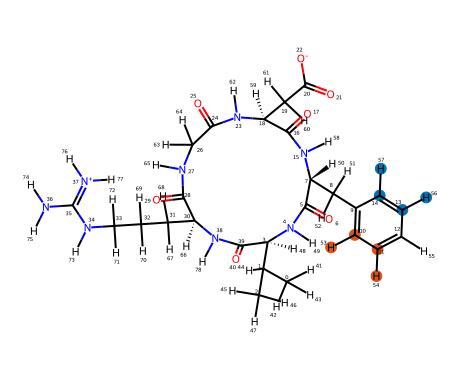

operation 2 exchanges (atom pairs): [(0, 2), (41, 45), (42, 46), (43, 47)]


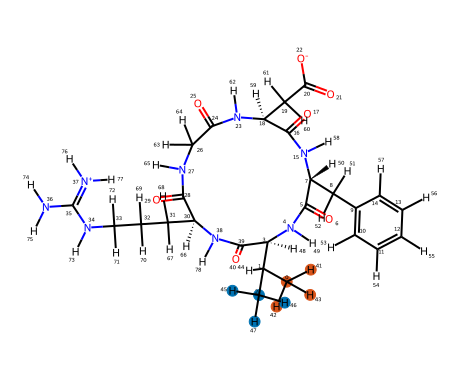

In [6]:
for k in (1, 2):
    info = draw_symmetry_operation(desc, k, output=scratch / f"op{k}.png")
    print(f"operation {k} exchanges (atom pairs):", info["exchanged_pairs"])
    display(Image(filename=str(scratch / f"op{k}.png")))

## 4. Clustering

The default `t_hdbscan` call: the symmetry-aware distance, a mass floor of 1 % of the fitted frames
(`min_cluster_size` 41 of 4002) and `min_samples` 40, and the 18-of-20 vote.

In [7]:
names = list(BACKBONE_AND_SYMMETRIC)
tors = md.compute_dihedrals(traj, list(BACKBONE_AND_SYMMETRIC.values()))
fit = t_hdbscan(tors, molecule=mol, torsion_definitions=definitions, coordinates=traj,
                atom_mapping=mapping).fit()
s = fit.summary()
print(f"{s['n_fit_frames']} frames, {s['n_clusters']} clusters, min_cluster_size "
      f"{s['settings']['min_cluster_size']}, min_samples {s['settings']['min_samples']}")
pd.DataFrame([{"cluster": group_name(c), "frames": int((fit.labels_ == c).sum()),
               "mass": round(float(fit.cluster_mass_[c]), 4)} for c in range(fit.n_clusters_)]
             + [{"cluster": "density noise", "frames": int((fit.labels_ == -2).sum()),
                 "mass": round(float(fit.noise_mass_), 4)},
                {"cluster": "ambiguous", "frames": int((fit.labels_ == -1).sum()),
                 "mass": round(float(fit.ambiguous_mass_), 4)}])

4002 frames, 2 clusters, min_cluster_size 41, min_samples 40


,cluster,frames,mass
0,A,3338,0.8341
1,B,580,0.1449
2,density noise,84,0.0210
3,ambiguous,0,0.0000


## 5. One reference, or two levels

The reference is the density peak of the largest cluster. `margin` is the second-best labelling's
distance minus the best; a small margin means the choice for that frame is arbitrary.

In [8]:
ref = fit.density_peak(0)
one = fit.align_all()
two = fit.align_all(per_cluster=True)
print(f"reference: frame {ref}, cluster {group_name(int(fit.labels_[ref]))}, core distance {fit.core_distance_[ref]:.3f}")
rows = []
for name, al in (("one reference", one), ("two levels", two)):
    for c in range(fit.n_clusters_):
        m = fit.labels_ == c
        used = np.bincount(al["operations"][m], minlength=len(desc.operations)) / m.sum()
        rows.append({"alignment": name, "cluster": group_name(c), "peak used": int(al["cluster_references"][c]),
                     **{f"op {k}": round(float(used[k]), 3) for k in range(len(desc.operations))},
                     "mean distance, no relabelling": round(float(al["distance_identity"][m].mean()), 3),
                     "mean distance, nearest": round(float(al["distance"][m].mean()), 3),
                     "margin < 0.1": round(float((al["margin"][m] < 0.1).mean()), 3)})
pd.DataFrame(rows)

reference: frame 830, cluster A, core distance 0.629


,alignment,cluster,peak used,op 0,op 1,op 2,op 3,"mean distance, no relabelling","mean distance, nearest",margin < 0.1
0,one reference,A,830,0.296,0.285,0.222,0.198,2.330,1.789,0.018
1,one reference,B,830,0.226,0.245,0.236,0.293,3.845,3.477,0.038
2,two levels,A,830,0.296,0.285,0.222,0.198,2.330,1.789,0.018
3,two levels,B,4,0.229,0.245,0.233,0.293,2.549,1.949,0.028


## 6. The torsions that carry the symmetry

The four columns of the two orbits, as stored and in the two-level labelling. The stored valine chi1
is bimodal because the two methyls can be named either way; the stored phenyl chi2 has two peaks half
a turn apart for the same reason.

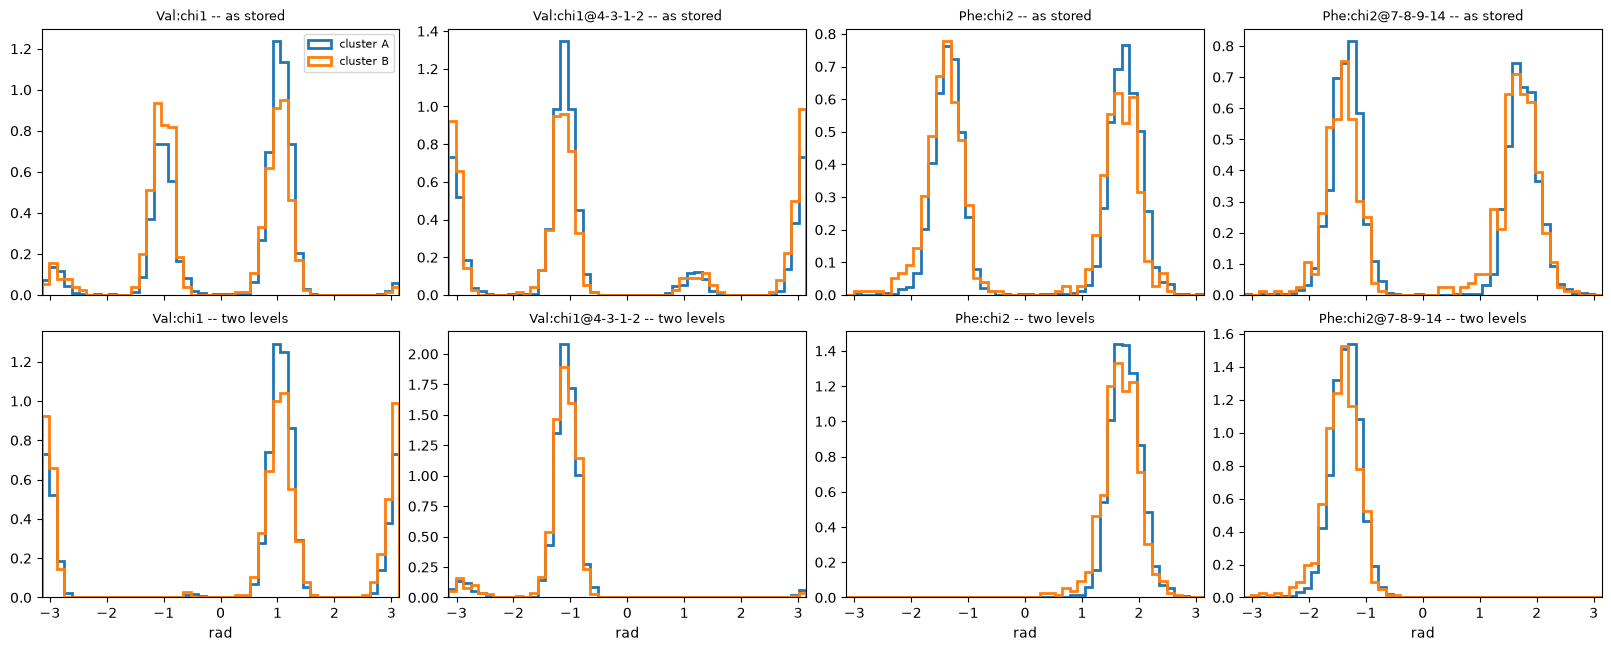

In [9]:
edges = np.linspace(-np.pi, np.pi, 49)
palette = plt.get_cmap("tab10")
orbit_columns = [c for o in desc.orbits if len(o) > 1 for c in o]
fig, axes = plt.subplots(2, 4, figsize=(16, 6.4), layout="constrained", sharex=True)
for r, (title, theta) in enumerate((("as stored", fit.closed_theta_), ("two levels", two["angles"]))):
    for j, col in enumerate(orbit_columns):
        for k in range(fit.n_clusters_):
            axes[r, j].hist(theta[fit.labels_ == k, col], bins=edges, density=True, histtype="step",
                            lw=2.0, color=palette(k), label=f"cluster {group_name(k)}")
        axes[r, j].set_xlim(-np.pi, np.pi)
        axes[r, j].set_title(f"{desc.names[col]} -- {title}", fontsize=9)
for j in range(4):
    axes[1, j].set_xlabel("rad")
axes[0, 0].legend(fontsize=8)
plt.show()

## 7. Fold one angle? The test, orbit by orbit

For each orbit, the number of **distinct** images of its first column that fall inside a window of
width pi centred on the reference value. A single-column fold is a valid fundamental domain for the
orbit only if that number is exactly one for every frame.

In [10]:
wrap = lambda x: np.angle(np.exp(1j * x))
rows = []
for orbit in desc.orbits:
    if len(orbit) < 2:
        continue
    first = orbit[0]
    centre = fit.closed_theta_[ref, first]
    images = sorted({op.sigma[first] for op in desc.operations})
    inside = sum((np.abs(wrap(fit.closed_theta_[:, k] - centre)) < np.pi / 2).astype(int) for k in images)
    frac = np.bincount(inside, minlength=3) / inside.size
    spacing = np.rad2deg(np.abs(wrap(fit.closed_theta_[:, orbit[1]] - fit.closed_theta_[:, first])))
    rows.append({"orbit": " / ".join(desc.names[c] for c in orbit),
                 "no image in window": round(float(frac[0]), 4), "exactly one": round(float(frac[1]), 4),
                 "two": round(float(frac[2]), 4),
                 "spacing of the pair, median (deg)": round(float(np.median(spacing)), 1)})
pd.DataFrame(rows)

,orbit,no image in window,exactly one,two,"spacing of the pair, median (deg)"
0,Val:chi1 / Val:chi1@4-3-1-2,0.3741,0.6259,0.0000,122.2
1,Phe:chi2 / Phe:chi2@7-8-9-14,0.0005,0.9993,0.0002,175.0


The phenyl pair passes: its two columns are half a turn apart, so one of them always falls in the
window. The valine pair fails: its two methyl torsions are about 120 degrees apart, a single window
catches neither for a large share of frames, and a fold of one angle is not a fundamental domain. The
two-level Dirichlet rule has no such condition.

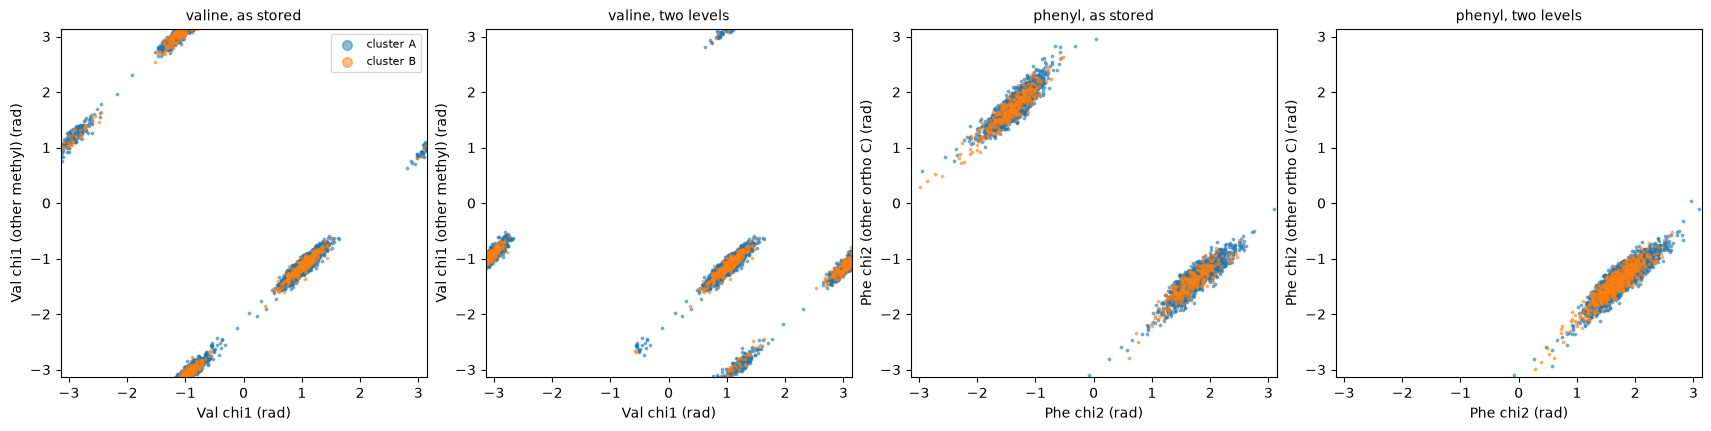

In [11]:
v0, v1 = (desc.names.index("Val:chi1"), desc.names.index("Val:chi1@4-3-1-2"))
f0, f1 = (desc.names.index("Phe:chi2"), desc.names.index("Phe:chi2@7-8-9-14"))
fig, axes = plt.subplots(1, 4, figsize=(17, 4.2), layout="constrained")
for ax, (title, th, i, j, lab) in zip(axes, [
        ("valine, as stored", fit.closed_theta_, v0, v1, ("Val chi1", "Val chi1 (other methyl)")),
        ("valine, two levels", two["angles"], v0, v1, ("Val chi1", "Val chi1 (other methyl)")),
        ("phenyl, as stored", fit.closed_theta_, f0, f1, ("Phe chi2", "Phe chi2 (other ortho C)")),
        ("phenyl, two levels", two["angles"], f0, f1, ("Phe chi2", "Phe chi2 (other ortho C)"))]):
    for k in range(fit.n_clusters_):
        sel = fit.labels_ == k
        ax.scatter(th[sel, i], th[sel, j], s=3, alpha=0.5, color=palette(k), label=f"cluster {group_name(k)}")
    ax.set_xlim(-np.pi, np.pi); ax.set_ylim(-np.pi, np.pi)
    ax.set_xlabel(lab[0] + " (rad)"); ax.set_ylabel(lab[1] + " (rad)"); ax.set_title(title, fontsize=10)
axes[0].legend(markerscale=4, fontsize=8)
plt.show()

## 8. The backbone, per cluster

Circular mean and circular standard deviation of phi, psi and omega in the two-level labelling. The
backbone columns are not moved by either operation, so these are the stored values.

In [12]:
def circ(values):
    R = np.hypot(np.sin(values).mean(), np.cos(values).mean())
    return np.rad2deg(np.arctan2(np.sin(values).mean(), np.cos(values).mean())), np.rad2deg(np.sqrt(-2.0 * np.log(max(R, 1e-12))))

backbone = [n for n in names if "chi" not in n]
rows = []
for n in backbone:
    row = {"torsion": n}
    for c in range(fit.n_clusters_):
        mean, sd = circ(two["selected"][fit.labels_ == c, names.index(n)])
        row[f"{group_name(c)} mean"], row[f"{group_name(c)} sd"] = round(mean, 1), round(sd, 1)
    rows.append(row)
pd.DataFrame(rows).set_index("torsion")

,A mean,A sd,B mean,B sd
torsion,,,,
Val:phi,-79.9,17.1,-82.8,17.3
Val:psi,-28.2,18.8,144.7,13.6
Val:omega,175.8,10.6,-179.6,9.7
Phe:phi,78.2,23.5,77.3,16.8
Phe:psi,-134.2,13.9,-122.7,25.4
Phe:omega,175.6,11.0,165.8,11.3
Asp:phi,-76.5,14.3,-78.6,30.0
Asp:psi,125.5,25.7,112.1,33.0
Asp:omega,-164.7,10.7,-160.1,9.5


## 9. Representative structures

The density peak of each cluster, superposed, hydrogens on carbon omitted.

51 atoms drawn, superposed: True


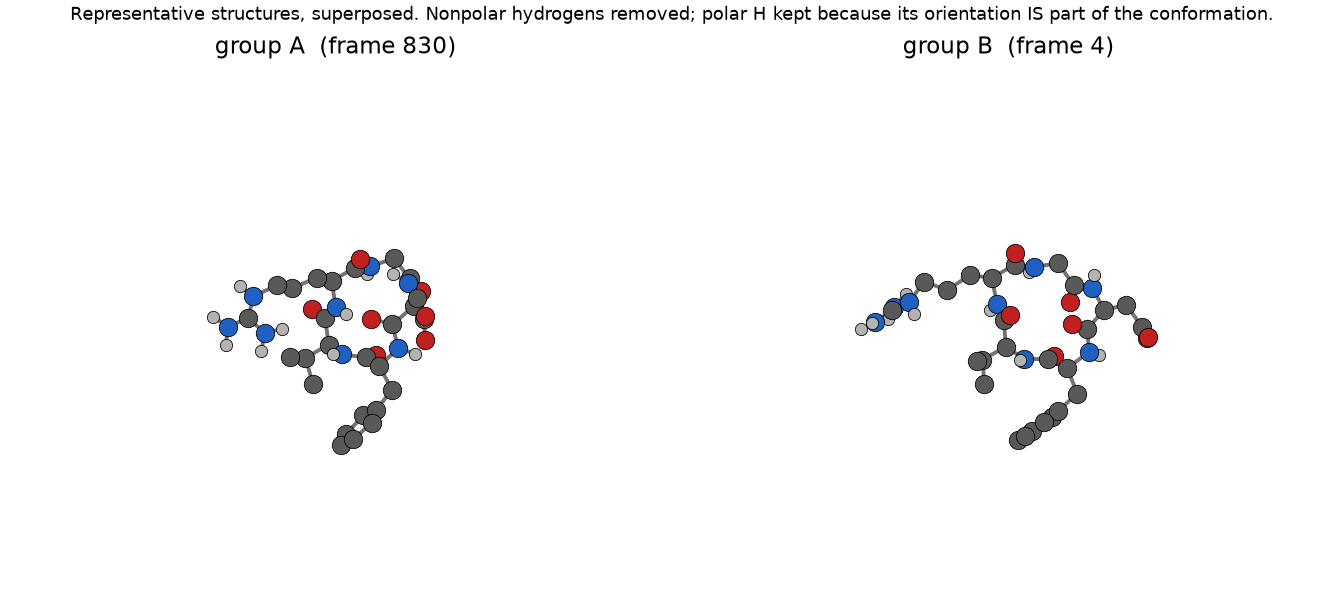

In [13]:
peaks = {group_name(c): two["cluster_references"][c] for c in range(fit.n_clusters_)}
keep = strip_nonpolar_hydrogens(traj)
info = draw_representative_structures(traj, peaks, output=scratch / "representatives.png", atom_indices=keep,
                                   label_atoms=False)
print(f"{info['n_atoms_drawn']} atoms drawn, superposed: {info['aligned']}")
display(Image(filename=str(scratch / "representatives.png")))

## 10. The choice of torsions matters

The same fit on the 17 columns above, on all 24 heavy-atom torsions (adding the Phe, Asp and Arg side
chains), and on the backbone and chi1 columns, each with `allow_single_cluster` on and off. The Arg
chi angles and the Asp carboxylate rotation are nearly uniform, which dilutes the density that
separates the backbone conformers.

In [14]:
everything = {**BACKBONE_AND_SYMMETRIC, **SIDE_CHAINS}
sets = {"17: backbone + symmetric columns (used above)": list(BACKBONE_AND_SYMMETRIC),
        "24: all heavy-atom torsions": list(everything),
        "20: backbone + every chi1 + the two symmetric columns": [n for n in everything
            if "chi" not in n or n.endswith("chi1") or n in ("Phe:chi2",)]}
rows = []
for label, sel in sets.items():
    defs = TorsionDefinitions(quads=tuple(everything[n] for n in sel), names=tuple(sel),
                              indexing="zero-based", units="radian")
    th = md.compute_dihedrals(traj, [everything[n] for n in sel])
    for flag in (True, False):
        f = t_hdbscan(th, molecule=mol, torsion_definitions=defs, coordinates=traj,
                      atom_mapping=mapping, allow_single_cluster=flag).fit()
        rows.append({"torsion set": label, "allow_single_cluster": flag, "clusters": f.n_clusters_,
                     "masses": [round(float(f.cluster_mass_[c]), 3) for c in range(f.n_clusters_)],
                     "noise": round(float(f.noise_mass_), 3)})
pd.DataFrame(rows)

,torsion set,allow_single_cluster,clusters,masses,noise
0,17: backbone + symmetric columns (used above),True,2,"[0.834, 0.145]",0.021
1,17: backbone + symmetric columns (used above),False,2,"[0.834, 0.145]",0.021
2,24: all heavy-atom torsions,True,1,[0.896],0.104
3,24: all heavy-atom torsions,False,2,"[0.814, 0.081]",0.104
4,20: backbone + every chi1 + the two symmetric ...,True,1,[0.977],0.023
5,20: backbone + every chi1 + the two symmetric ...,False,2,"[0.834, 0.143]",0.023
